In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [13]:
results = Path("../../results/implementation")
figures = results/"figures"
tables = results/"tables"

In [2]:
df = pd.read_csv("../../data/processed/real_estate_data_updated.csv")
print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Dataset shape: (414, 8)


,X1 transaction year,X1 transaction month,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012,December,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012,December,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013,August,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013,July,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012,November,5.0,390.56840,5,24.97937,121.54245,43.1


['X1 transaction year', 'X1 transaction month', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']


In [3]:
target = "Y house price of unit area"

numerical_features = [
    'X2 house age', 
    'X3 distance to the nearest MRT station', 
    'X4 number of convenience stores', 
    'X5 latitude', 
    'X6 longitude', 
]

categorical_features = [
    "X1 transaction year", 
    "X1 transaction month"
]

In [5]:
x_df = pd.get_dummies(
    df[numerical_features + categorical_features],
    columns=categorical_features,
    drop_first=True,
    dtype=float
)

y = df[target].to_numpy(dtype=float)

x = x_df.to_numpy(dtype=float)

print("Predictor matrix shape:", x.shape)
print("Target vector shape:", y.shape)

print("\nEncoded features:")
print(x_df.columns.tolist())

Predictor matrix shape: (414, 17)
Target vector shape: (414,)

Encoded features:
['X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'X1 transaction year_2013', 'X1 transaction month_August', 'X1 transaction month_December', 'X1 transaction month_February', 'X1 transaction month_January', 'X1 transaction month_July', 'X1 transaction month_June', 'X1 transaction month_March', 'X1 transaction month_May', 'X1 transaction month_November', 'X1 transaction month_October', 'X1 transaction month_September']


In [ ]:
# design matrix

x_design = np.column_stack([
    np.ones(x.shape[0]),
    x
])

coefficient_names = [
    "Intercept"
] + x_df.columns.tolist()

print("Design matrix shape:", x_design.shape)
print("Number of coefficient:", x_design.shape[1])


Design matrix shape: (414, 18)
Number of coefficient: 18


In [ ]:
# ols using normal equations

xtx = x_design.T @ x_design
xty = x_design.T @ y

beta_normal = np.linalg.solve(xtx, xty)

coefficient_normal = pd.DataFrame({
    "Featrue": coefficient_names, 
    "Coefficient": beta_normal
})

display(coefficient_normal)

,Featrue,Coefficient
0,Intercept,-8992.257848
1,X2 house age,-0.272789
2,X3 distance to the nearest MRT station,-0.004482
3,X4 number of convenience stores,1.153752
4,X5 latitude,233.004457
5,X6 longitude,-12.153848
6,X1 transaction year_2013,4694.606165
7,X1 transaction month_August,2.835504
8,X1 transaction month_December,4691.591360
9,X1 transaction month_February,0.752765


In [8]:
# generate predictions

y_pred_normal = x_design @ beta_normal

residual_normal = y - y_pred_normal

prediction_normal = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred_normal,
    "Residual": residual_normal
})

display(prediction_normal.head(10))

,Actual,Predicted,Residual
0,37.9,45.725401,-7.825401
1,42.2,46.381414,-4.181414
2,47.3,49.768741,-2.468741
3,54.8,50.428735,4.371265
4,43.1,46.657258,-3.557258
5,32.1,32.146685,-0.046685
6,40.3,39.745188,0.554812
7,46.7,44.235186,2.464814
8,18.8,10.819943,7.980057
9,22.1,32.003284,-9.903284


In [10]:
# evaluate model performance 

mse_normal = np.mean(residual_normal ** 2)

rmse_normal = np.sqrt(mse_normal)

mae_normal = np.mean(np.abs(residual_normal))

r2_normal = 1 - (
    np.sum(residual_normal ** 2) / 
    np.sum((y - np.mean(y)) ** 2)
)

print("OLS - Normal Equations")
print(f"MSE  : {mse_normal:.6f}")
print(f"RMSE : {rmse_normal:.6f}")
print(f"MAE  : {mae_normal:.6f}")
print(f"R²   : {r2_normal:.6f}")

OLS - Normal Equations
MSE  : 74.973033
RMSE : 8.658697
MAE  : 6.013422
R²   : 0.594059


In [ ]:
# numerical stability

condition_x = np.linalg.cond(x_design)

condition_xtx = np.linalg.cond(xtx)

print("Numerical Stability Analysis")

print(f"Condition number of x : {condition_x:.6f}")
print(f"Condition number of x.T @ x: {condition_xtx:.6f}")

Numerical Stability Analysis
Condition number of x : 9494350793774702592.000000
Condition number of x.T @ x: 285582885651266011136.000000


In [17]:
# matrix diagnostics

rows, cols = x_design.shape

matrix_rank = np.linalg.matrix_rank(x_design)

print("Matrix Dimensions:", x_design.shape)
print("Number of Columns:", cols)
print("matrix rank:", matrix_rank)
print("rank deficiency:", cols - matrix_rank)

Matrix Dimensions: (414, 18)
Number of Columns: 18
matrix rank: 17
rank deficiency: 1


In [23]:
# singular value analysis

singular_values = np.linalg.svd(
    x_design, compute_uv=False
)

print("Singular Values")
print(singular_values)

print("\nLargest Singular Value:", singular_values[0])
print("Smallest Singular Value:", singular_values[-1])

print(
    "\nCondition Number:", 
    singular_values[0] / singular_values[-1]
)

Singular Values
[3.38677197e+04 1.93320830e+03 2.29173092e+02 4.75780289e+01
 1.10397741e+01 7.33347032e+00 6.62100311e+00 6.00146548e+00
 5.92269007e+00 5.47036328e+00 5.30508592e+00 5.27575329e+00
 5.07802044e+00 4.85292107e+00 1.90526955e+00 2.00363540e-01
 1.55619613e-03 3.56714434e-15]

Largest Singular Value: 33867.71966863474
Smallest Singular Value: 3.5671443371190025e-15

Condition Number: 9.494350793774703e+18


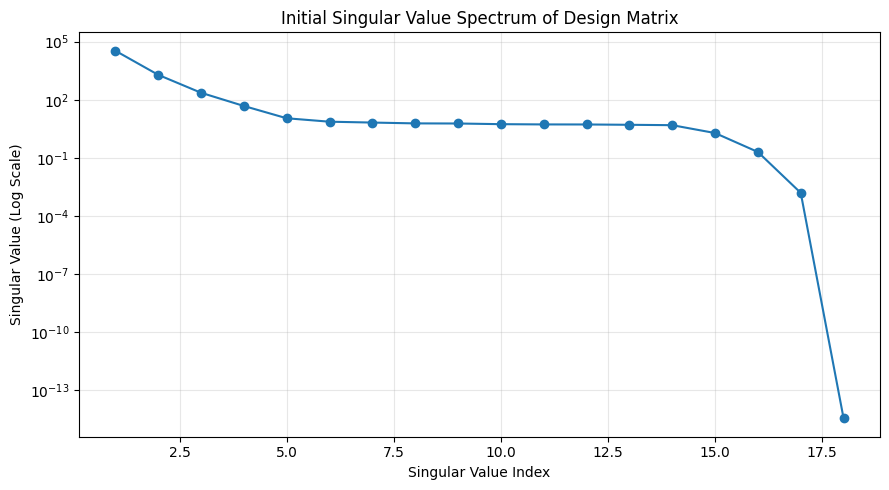

In [39]:
# vizualize the above results

plt.figure(figsize=(9, 5))
plt.semilogy(
    range(1, len(singular_values) + 1),
    singular_values,
    marker="o"
)

plt.title("Initial Singular Value Spectrum of Design Matrix")
plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value (Log Scale)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures /"ols_normal_equations_initial_singular_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [26]:
# year-month dependency investigation

year_month_table = pd.crosstab(
    df["X1 transaction year"],
    df["X1 transaction month"]
)

display(year_month_table)

X1 transaction month,April,August,December,February,January,July,June,March,May,November,October,September
X1 transaction year,,,,,,,,,,,,
2012,0,0,38,0,0,0,0,0,0,31,27,30
2013,32,23,0,46,28,47,58,25,29,0,0,0


In [27]:
# number of unique values and category frequencies

print("Transaction Year Distribution:")
print(df["X1 transaction year"].value_counts().sort_index())

print("\nTransaction Month Distribution:")
print(df["X1 transaction month"].value_counts().sort_index())

Transaction Year Distribution:
X1 transaction year
2012    126
2013    288
Name: count, dtype: int64

Transaction Month Distribution:
X1 transaction month
April        32
August       23
December     38
February     46
January      28
July         47
June         58
March        25
May          29
November     31
October      27
September    30
Name: count, dtype: int64


In [28]:
# numerical solution validation

normal_equation_residual = (
    xtx @ beta_normal - xty
)

residual_norm = np.linalg.norm(
    normal_equation_residual
)

print("Normal Equation Residual Norm:", residual_norm)

print(
    "Relative Normal Equation Residual:",
    residual_norm / np.linalg.norm(xty)
)

Normal Equation Residual Norm: 1.1862897803484008e-07
Relative Normal Equation Residual: 9.54950740855017e-15


In [30]:
# compare with normal equation solution against a least squares reference

beta_lstsq, residual_lstsq, rank_lstsq, singular_lstsq = (
    np.linalg.lstsq(x_design, y, rcond=None)
)

print("Rank from lstsq:", rank_lstsq)

print(
    "Coefficient Difference Norm", 
    np.linalg.norm(beta_normal - beta_lstsq)
)

print(
    "Prediction Difference Norm:",
    np.linalg.norm(
        x_design @ beta_normal - x_design @ beta_lstsq
    )
)

Rank from lstsq: 17
Coefficient Difference Norm 13250.287942265053
Prediction Difference Norm: 4.5157942316989765e-07


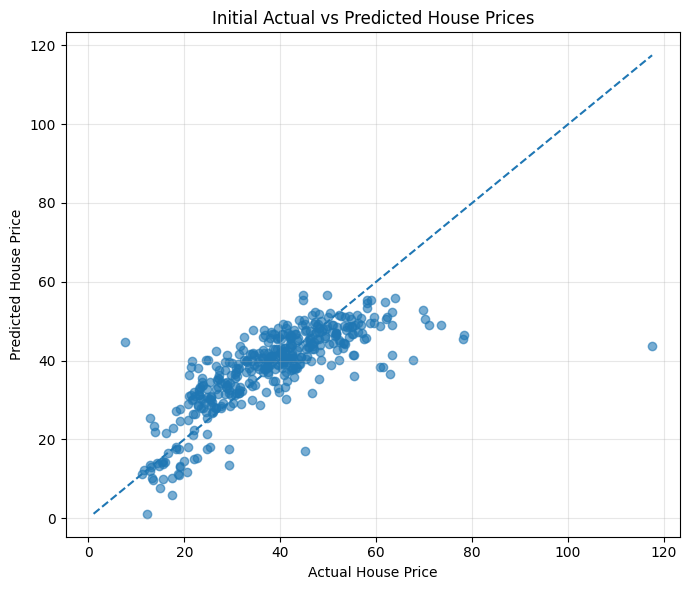

In [40]:
# residual analysis

plt.figure(figsize=(7, 6))

plt.scatter(
    y, y_pred_normal, alpha=0.6
)

min_value = min(y.min(), y_pred_normal.min())
max_value = max(y.max(), y_pred_normal.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Initial Actual vs Predicted House Prices")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures/"ols_normal_equations_initial_actual_vs_predicted.png",
    dpi=300, 
    bbox_inches="tight"
)

plt.show()
plt.close()

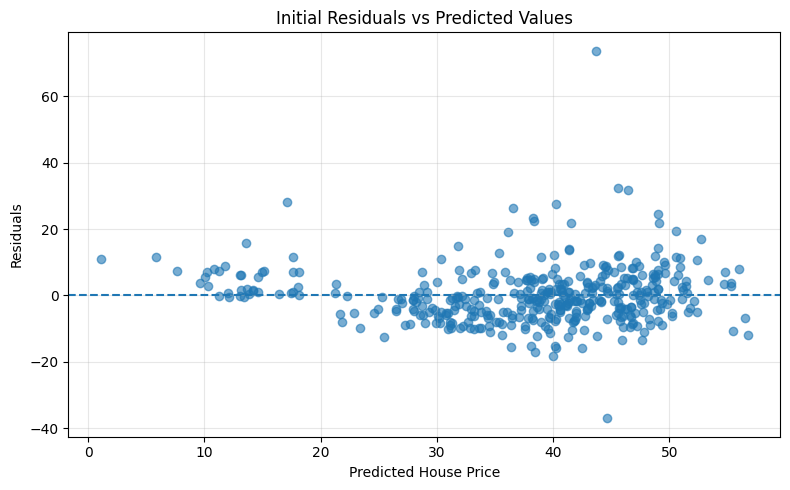

In [41]:
# plot residuals against predicted values

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_normal,
    residual_normal,
    alpha=0.6
)

plt.axhline(0, linestyle="--")

plt.title("Initial Residuals vs Predicted Values")
plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures / "ols_normal_equations_initial_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [ ]:
# additional diagnostics

diagnostics = pd.DataFrame({
    "Metric": [
        "Number of Observations",
        "Number of Predictors Including Intercept",
        "Matrix Rank",
        "Rank Deficiency",
        "Condition Number X",
        "Condition Number XtX",
        "Smallest Singular Value",
        "Largest Singular Value",
        "Normal Equation Residual Norm",
        "Coefficient Difference from lstsq"
    ],
    "Value": [
        rows,
        cols,
        matrix_rank,
        cols - matrix_rank,
        condition_x,
        condition_xtx,
        singular_values[-1],
        singular_values[0],
        residual_norm,
        np.linalg.norm(beta_normal - beta_lstsq)
    ]
})

diagnostics.to_csv(
    tables / "ols_normal_equations_diagnostics.csv",
    index=False
)

# Experiment 2: Revised OLS Model

## 2.1 Motivation for Model Revision

The initial OLS implementation included transaction year and transaction month as categorical predictors using one-hot encoding.

The subsequent numerical investigation revealed that the resulting design matrix was rank-deficient. Its dimensions were (414, 18), whereas its numerical rank was 17.

Further examination of the year-month distribution identified an exact linear dependency between the transaction year and month dummy variables in the presence of an intercept.

This dependency resulted in non-unique coefficient estimates and an extremely large condition number.

## 2.2 Revised Feature Specification

To address the identified rank deficiency, transaction year is excluded from the revised predictor set, while transaction month is retained as a categorical variable.

The revised model consists of:

- Five numerical predictors: house age, distance to the nearest MRT station, number of convenience stores, latitude and longitude.
- One categorical predictor: transaction month.
- An intercept term.

The revised design matrix will be examined for numerical rank, conditioning and regression performance.

## 2.3 Revised OLS Estimation

The Ordinary Least Squares estimator is again obtained using the normal equations:

\[
X^T X \hat{\beta}=X^T y
\]

The revised specification allows us to investigate whether removing the redundant categorical representation resolves the rank deficiency.

In [44]:
numerical_features_revised = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude"
]

categorical_features_revised = [
    "X1 transaction month"
]

In [ ]:
# revised design matrix

x_df_revised = pd.get_dummies(
    df[numerical_features_revised + categorical_features_revised],
    columns=categorical_features_revised,
    drop_first=True,
    dtype=float
)

x_revised = x_df_revised.to_numpy(dtype=float)

y = df[target].to_numpy(dtype=float)

x_design_revised = np.column_stack([
    np.ones(x_revised.shape[0]),
    x_revised
])

coefficient_names_revised = (
    ["Intercept"] + x_df_revised.columns.tolist()
)

print("Revised design matrix shape:", x_design_revised.shape)
print("Number of coefficients:", x_design_revised.shape[1])

print("\nRevised features:")
print(coefficient_names_revised)

Revised design matrix shape: (414, 17)
Number of coefficients: 17

Revised features:
['Intercept', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'X1 transaction month_August', 'X1 transaction month_December', 'X1 transaction month_February', 'X1 transaction month_January', 'X1 transaction month_July', 'X1 transaction month_June', 'X1 transaction month_March', 'X1 transaction month_May', 'X1 transaction month_November', 'X1 transaction month_October', 'X1 transaction month_September']


In [46]:
# solve the normal equations

xtx_revised = x_design_revised.T @ x_design_revised
xty_revised = x_design_revised.T @ y

beta_normal_revised = np.linalg.solve(
    xtx_revised,
    xty_revised
)

coefficient_normal_revised = pd.DataFrame({
    "Feature": coefficient_names_revised,
    "Coefficient": beta_normal_revised
})

display(coefficient_normal_revised)

,Feature,Coefficient
0,Intercept,-4297.651617
1,X2 house age,-0.272789
2,X3 distance to the nearest MRT station,-0.004482
3,X4 number of convenience stores,1.153752
4,X5 latitude,233.004458
5,X6 longitude,-12.153849
6,X1 transaction month_August,2.835504
7,X1 transaction month_December,-3.014805
8,X1 transaction month_February,0.752765
9,X1 transaction month_January,-0.885104


In [47]:
# prediction and residuals

y_pred_revised = x_design_revised @ beta_normal_revised

residual_revised = y - y_pred_revised

prediction_revised = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred_revised,
    "Residual": residual_revised
})

display(prediction_revised.head(10))

,Actual,Predicted,Residual
0,37.9,45.725401,-7.825401
1,42.2,46.381414,-4.181414
2,47.3,49.768741,-2.468741
3,54.8,50.428735,4.371265
4,43.1,46.657258,-3.557258
5,32.1,32.146685,-0.046685
6,40.3,39.745188,0.554812
7,46.7,44.235186,2.464814
8,18.8,10.819943,7.980057
9,22.1,32.003284,-9.903284


In [48]:
# revised model evaluation

mse_revised = np.mean(residual_revised ** 2)
rmse_revised = np.sqrt(mse_revised)
mae_revised = np.mean(np.abs(residual_revised))

r2_revised = 1 - (
    np.sum(residual_revised ** 2) /
    np.sum((y - np.mean(y)) ** 2)
)

print("OLS - Revised Normal Equations")
print(f"MSE  : {mse_revised:.6f}")
print(f"RMSE : {rmse_revised:.6f}")
print(f"MAE  : {mae_revised:.6f}")
print(f"R²   : {r2_revised:.6f}")

OLS - Revised Normal Equations
MSE  : 74.973033
RMSE : 8.658697
MAE  : 6.013422
R²   : 0.594059


In [51]:
# revised numerical diagnostics

rank_revised = np.linalg.matrix_rank(x_design_revised)

singular_values_revised = np.linalg.svd(
    x_design_revised,
    compute_uv=False
)

condition_x_revised = np.linalg.cond(x_design_revised)

condition_xtx_revised = np.linalg.cond(xtx_revised)

print("Revised Numerical Stability Analysis")

print("Matrix dimensions:", x_design_revised.shape)
print("Matrix rank:", rank_revised)
print(
    "Rank deficiency:",
    x_design_revised.shape[1] - rank_revised
)

print("Condition number of X:", condition_x_revised)
print("Condition number of X.T @ X:", condition_xtx_revised)

print("Largest singular value:", singular_values_revised[0])
print("Smallest singular value:", singular_values_revised[-1])

Revised Numerical Stability Analysis
Matrix dimensions: (414, 17)
Matrix rank: 17
Rank deficiency: 0
Condition number of X: 23840107.52927059
Condition number of X.T @ X: 568346163503763.0
Largest singular value: 33867.71837097972
Smallest singular value: 0.0014206193629536844


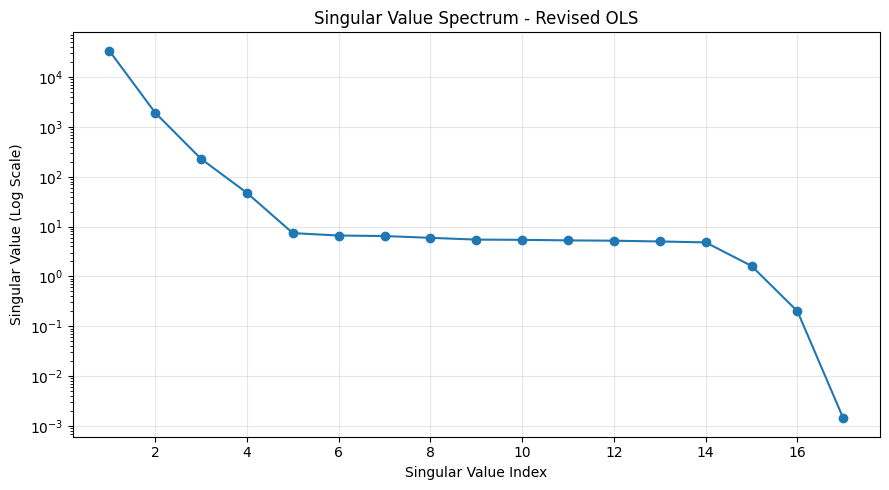

In [64]:
# revised singular value decomposition

plt.figure(figsize=(9, 5))

plt.semilogy(
    range(1, len(singular_values_revised) + 1),
    singular_values_revised,
    marker="o"
)

plt.title("Singular Value Spectrum - Revised OLS")
plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value (Log Scale)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures/"ols_normal_equations_revised_singular_values.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()
plt.close()

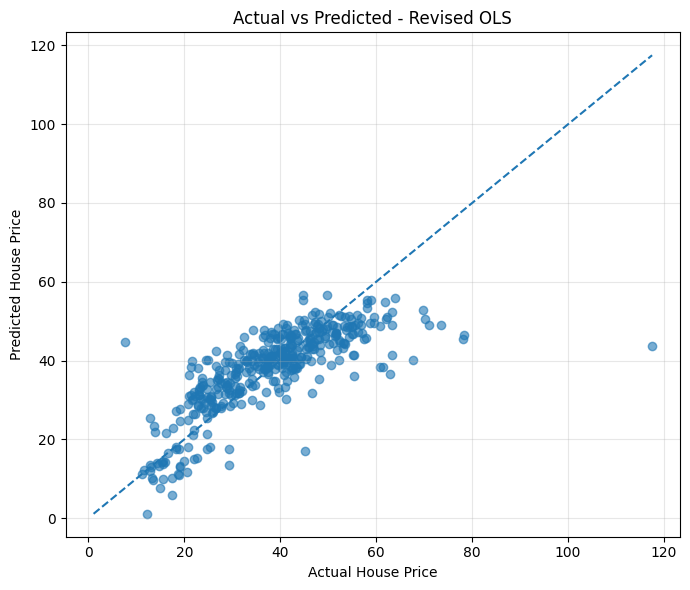

In [63]:
# revised actual vs predicted plot

plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    y_pred_revised,
    alpha=0.6
)

min_value = min(y.min(), y_pred_revised.min())
max_value = max(y.max(), y_pred_revised.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted - Revised OLS")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures/"ols_normal_equations_revised_actual_vs_predicted.png",
    dpi = 300,
    bbox_inches = "tight"
)
plt.show()
plt.close()

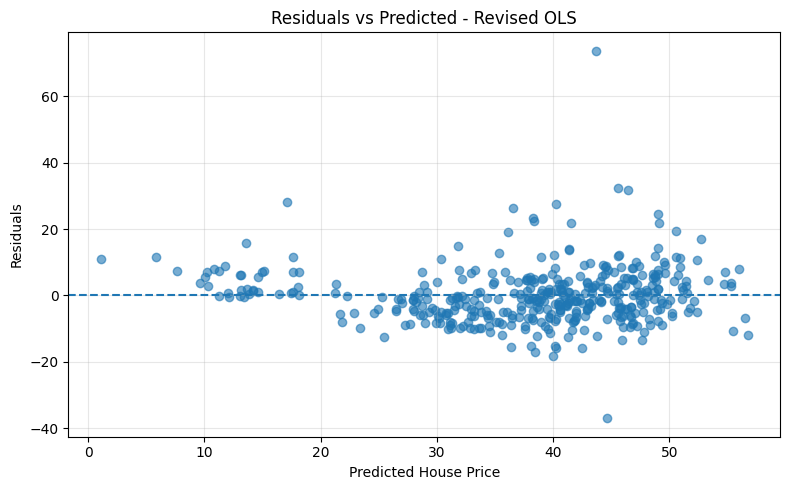

In [59]:
# revised residuals vs predicted plot

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_revised,
    residual_revised,
    alpha=0.6
)

plt.axhline(0, linestyle="--")

plt.title("Residuals vs Predicted - Revised OLS")
plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures/"ols_normal_equations_revised_residuals.png",
    dpi = 300,
    bbox_inches = "tight"
)
plt.show()
plt.close()

In [55]:
# revised normal equation validation

normal_equation_residual_revised = (
    xtx_revised @ beta_normal_revised - xty_revised
)

print(
    "Normal Equation Residual Norm:",
    np.linalg.norm(normal_equation_residual_revised)
)

print(
    "Relative Normal Equation Residual:",
    np.linalg.norm(normal_equation_residual_revised)
    / np.linalg.norm(xty_revised)
)

Normal Equation Residual Norm: 1.1426012315711826e-07
Relative Normal Equation Residual: 9.197822910860357e-15


## 2.4 Comparison of Initial and Revised OLS Models

The initial and revised OLS specifications are compared using their numerical stability and training-data regression metrics.

The comparison considers matrix rank, condition numbers, MSE, RMSE, MAE and coefficient identifiability.

This analysis helps assess the numerical consequences of removing the redundant categorical representation.

In [56]:
model_comparison = pd.DataFrame({
    "Metric": [
        "Number of Columns",
        "Matrix Rank",
        "Rank Deficiency",
        "Condition Number X",
        "Condition Number XtX",
        "MSE",
        "RMSE",
        "MAE",
        "R2"
    ],
    "Initial Model": [
        x_design.shape[1],
        matrix_rank,
        x_design.shape[1] - matrix_rank,
        condition_x,
        condition_xtx,
        mse_normal,
        rmse_normal,
        mae_normal,
        r2_normal
    ],
    "Revised Model": [
        x_design_revised.shape[1],
        rank_revised,
        x_design_revised.shape[1] - rank_revised,
        condition_x_revised,
        condition_xtx_revised,
        mse_revised,
        rmse_revised,
        mae_revised,
        r2_revised
    ]
})

display(model_comparison)

,Metric,Initial Model,Revised Model
0,Number of Columns,1.800000e+01,1.700000e+01
1,Matrix Rank,1.700000e+01,1.700000e+01
2,Rank Deficiency,1.000000e+00,0.000000e+00
3,Condition Number X,9.494351e+18,2.384011e+07
4,Condition Number XtX,2.855829e+20,5.683462e+14
5,MSE,7.497303e+01,7.497303e+01
6,RMSE,8.658697e+00,8.658697e+00
7,MAE,6.013422e+00,6.013422e+00
8,R2,5.940586e-01,5.940586e-01


# 3. Final Results and Export

The results from both OLS experiments are exported for reproducibility and subsequent comparison with QR decomposition and Singular Value Decomposition.

The initial experiment's diagnostic results are preserved, while the revised model's coefficients, predictions, evaluation metrics and numerical diagnostics are saved separately.

In [57]:
# Revised coefficients
coefficient_normal_revised.to_csv(
    tables / "ols_revised_coefficients.csv",
    index=False
)

# Revised predictions
prediction_revised.to_csv(
    tables / "ols_revised_predictions.csv",
    index=False
)

# Revised evaluation metrics
revised_metrics = pd.DataFrame({
    "Method": ["Normal Equations - Revised"],
    "MSE": [mse_revised],
    "RMSE": [rmse_revised],
    "MAE": [mae_revised],
    "R2": [r2_revised]
})

revised_metrics.to_csv(
    tables / "ols_revised_metrics.csv",
    index=False
)

# Revised diagnostics
revised_diagnostics = pd.DataFrame({
    "Metric": [
        "Matrix Rank",
        "Number of Columns",
        "Rank Deficiency",
        "Condition Number X",
        "Condition Number XtX",
        "Smallest Singular Value",
        "Normal Equation Residual Norm"
    ],
    "Value": [
        rank_revised,
        x_design_revised.shape[1],
        x_design_revised.shape[1] - rank_revised,
        condition_x_revised,
        condition_xtx_revised,
        singular_values_revised[-1],
        np.linalg.norm(normal_equation_residual_revised)
    ]
})

revised_diagnostics.to_csv(
    tables / "ols_revised_diagnostics.csv",
    index=False
)

# Initial vs revised comparison
model_comparison.to_csv(
    tables / "ols_initial_vs_revised_comparison.csv",
    index=False
)

# Revised feature names
pd.DataFrame({
    "Feature": coefficient_names_revised
}).to_csv(
    tables / "ols_revised_feature_names.csv",
    index=False
)

print("All revised OLS results saved successfully.")

All revised OLS results saved successfully.
